In [1]:
import numpy as np
import os
os.environ["OMP_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
from petitRADTRANS.fortran_radtrans_core import fortran_radtrans_core
import petitRADTRANS.physical_constants as cst 

from petitRADTRANS.radtrans import Radtrans
from petitRADTRANS.retrieval.parameter import Parameter
from petitRADTRANS.retrieval.models import emission_model_diseq, guillot_emission
import petitRADTRANS.plotlib.style as ps
ps.set_petitradtrans_plot_style()
path_input_data = "/Users/nasedkin/python-packages/petitRADTRANS/input_data/"
buffer = np.genfromtxt(os.path.join(path_input_data, 'opa_input_files', 'g_comb_grid.dat'))


#from numba import jit
from jax import config
config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax import grad, jit, vmap, lax, ShapeDtypeStruct, pure_callback, debug

import petitRADTRANS.jax_radtrans as jrt

INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/opt/anaconda3/envs/jaxprt/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file), '/usr/local/lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache)


Using pRT Plotting style!


In [2]:
"""# Call the Fortran subroutine
jflux, _ = jrt.compute_feautrier_radiative_transfer(
    jax_frequency_bin_edges,
    temperatures,
    weights_gauss,
    emission_cos_angles,
    emission_cos_angles_weights,
    optical_depths,
    photon_destruction_probabilities,
    'planetary_ave',  # emission_geometry
    stellar_intensity,
    star_irradiation_cos_angle,
    reflectances,
    emissivities,
    False,  # return_contribution
)"""


"# Call the Fortran subroutine\njflux, _ = jrt.compute_feautrier_radiative_transfer(\n    jax_frequency_bin_edges,\n    temperatures,\n    weights_gauss,\n    emission_cos_angles,\n    emission_cos_angles_weights,\n    optical_depths,\n    photon_destruction_probabilities,\n    'planetary_ave',  # emission_geometry\n    stellar_intensity,\n    star_irradiation_cos_angle,\n    reflectances,\n    emissivities,\n    False,  # return_contribution\n)"

In [30]:
import sys
from time import sleep
from petitRADTRANS.jax_physics import compute_planck_function_integral
from petitRADTRANS.jax_math import tridag_own
from petitRADTRANS.fortran_radtrans_core import math as fmath
from petitRADTRANS.fortran_radtrans_core import physics as fphysics


# Constants
ITER_SCAT = 1000
TINIEST = jnp.finfo(jnp.float64).tiny
PI_4 = 4 * jnp.pi
N_ITERATIONS_MIN = 9
CONVERGENCE_THRESHOLD = 1e-3

#@jit
def m_approximate_ng_source(source_n, source_n1, source_n2, source_n3, source):
    n_g = 1
    n_frequencies_bin_edges = 1
    n_layers = source.shape[-1]
    huge_q = jnp.sqrt(jnp.finfo(jnp.float64).max)
    tiniest = jnp.finfo(jnp.float64).tiny

    source_buff = jnp.zeros((n_g,n_frequencies_bin_edges,n_layers))

    def process_frequency(i_freq, source_buff):
        def process_ng(i_ng, source_buff):
            tn = source_n
            tn1 = source_n1
            tn2 = source_n2
            tn3 = source_n3

            Q1 = tn - 2.0 * tn1 + tn2
            Q2 = tn - tn1 - tn2 + tn3
            Q3 = tn - tn1

            Q1 = Q1.at[0].set(0.0)
            Q2 = Q2.at[0].set(0.0)
            Q3 = Q3.at[0].set(0.0)

            A1 = jnp.minimum(jnp.sum(Q1 * Q1), huge_q)
            A2 = jnp.minimum(jnp.sum(Q2 * Q1), huge_q)
            B1 = jnp.minimum(jnp.sum(Q1 * Q2), huge_q)
            B2 = jnp.minimum(jnp.sum(Q2 * Q2), huge_q)
            C1 = jnp.minimum(jnp.sum(Q1 * Q3), huge_q)
            C2 = jnp.minimum(jnp.sum(Q2 * Q3), huge_q)

            AB_denominator = A1 * B2 - A2 * B1

            def nan_handling(source_buff):
                return source_buff

            def compute_source(source_buff):
                a = (C1 * B2 - C2 * B1) / AB_denominator
                b = (C2 * A1 - C1 * A2) / AB_denominator

                temp_buff = jnp.maximum((1.0 - a - b) * tn + a * tn1 + b * tn2, 0.0)
                source_buff = source_buff.at[i_ng, i_freq, :].set(temp_buff)
                return source_buff

            source_buff = lax.cond(
                AB_denominator < tiniest,
                nan_handling,
                lambda sb: lax.cond(
                    (jnp.abs(A1) >= 1e-250) & (jnp.abs(A2) >= 1e-250) & (jnp.abs(B1) >= 1e-250) & 
                    (jnp.abs(B2) >= 1e-250) & (jnp.abs(C1) >= 1e-250) & (jnp.abs(C2) >= 1e-250),
                    compute_source,
                    lambda sb: sb.at[i_ng, i_freq, :].set(source),
                    source_buff
                ),
                source_buff
            )
            return source_buff
        
        source_buff = lax.fori_loop(0, n_g, process_ng, source_buff)
        return source_buff

    source_buff = lax.fori_loop(0, n_frequencies_bin_edges, process_frequency, source_buff)
    return source_buff[0,0]

def solve_tridiagonal_system(a,b,c,d):
    result_shape = ShapeDtypeStruct(d.shape, d.dtype)
    return pure_callback(fmath.solve_tridiagonal_system, result_shape, a,b,c,d)

def ng_acceleration(
        i_iter_scat, 
        source, 
        l, 
        i, 
        source_planet_scat_n,
        source_planet_scat_n1, 
        source_planet_scat_n2, 
        source_planet_scat_n3):
    
    # Ng acceleration
    def true_fun(vals):
        source, l, i, source_planet_scat_n, source_planet_scat_n1, source_planet_scat_n2, source_planet_scat_n3 = vals
        source_planet_scat_n = source[:, l, i]
        updated_source = source.at[:, l, i].set(m_approximate_ng_source(
            source_planet_scat_n, 
            source_planet_scat_n1, 
            source_planet_scat_n2, 
            source_planet_scat_n3, 
            source[:, l, i]
        ))
        return updated_source, updated_source[:, l, i], source_planet_scat_n

    # Default to just passing the input arrays
    def false_fun(vals):
        source, l, i, source_planet_scat_n, source_planet_scat_n1, source_planet_scat_n2, source_planet_scat_n3 = vals
        return source, source[:, l, i], source_planet_scat_n

    # Only accelerate every 4th iteration
    condition = (i_iter_scat % 4 == 0)
    source, r, source_planet_scat_n = lax.cond(
        condition,
        true_fun,
        false_fun, 
        (source, l, i, source_planet_scat_n, source_planet_scat_n1, source_planet_scat_n2, source_planet_scat_n3)
    )
    return source, r, source_planet_scat_n

def compute_feautrier_radiative_transfer(
    frequencies_bin_edges, 
    temperatures, 
    weights_gauss, 
    emission_cos_angles, 
    emission_cos_angles_weights,
    optical_depths, 
    photon_destruction_probabilities, 
    emission_geometry, 
    stellar_intensity,
    star_irradiation_cos_angle, 
    reflectances, 
    emissivities
):
    # Constants
    # TODO: get from single shape call
    n_angles = emission_cos_angles.shape[0]
    n_frequencies_bin_edges = frequencies_bin_edges.shape[0]
    n_layers = temperatures.shape[0]
    n_g = weights_gauss.shape[0]
    
    surf_refl_2 = 2 * reflectances
    mu_weight = emission_cos_angles * emission_cos_angles_weights

    # Initialize arrays
    I_star_calc = jnp.zeros((n_g, n_layers, n_angles, n_frequencies_bin_edges - 1))
    J_star_ini = jnp.zeros((n_g, n_layers, n_frequencies_bin_edges - 1))

    # Reshape photon_destruction_probabilities
    photon_destruction_probabilities_ = jnp.transpose(photon_destruction_probabilities, (1, 2, 0))

    # Compute Planck function integral
    planck = compute_planck_function_integral(temperatures, frequencies_bin_edges)

    # Geometry coefficient
    # TODO: rewrite to take in geometry coefficient as an argument.
    if emission_geometry == 'dayside_ave':
        geometry_coefficient = 0.5
    elif emission_geometry == 'planetary_ave':
        geometry_coefficient = 0.25
    elif emission_geometry == 'non-isotropic':
        geometry_coefficient = -1.0
    else:
        raise ValueError("Invalid geometry")

    # Stellar attenuation calculation
    if geometry_coefficient > 0:
        for i in range(n_frequencies_bin_edges - 1):
            for i_mu in range(n_angles):
                I_star_calc = I_star_calc.at[:, :, i_mu, i].set(
                    geometry_coefficient 
                    * jnp.abs(stellar_intensity[i]) 
                    * jnp.exp(-optical_depths[:, i, :]/ emission_cos_angles[i_mu])
                    )
                J_star_ini = J_star_ini.at[:, :, i].add(0.5 * I_star_calc[:, :, i_mu, i] * emission_cos_angles_weights[i_mu])
    else:
        for i in range(n_frequencies_bin_edges - 1):
            J_star_ini = J_star_ini.at[:, :, i].set(
                jnp.abs(stellar_intensity[i] / 4
                        * jnp.exp(-optical_depths[:, i, :] / star_irradiation_cos_angle))
                        )

    # Prevent issues with negative or 0 photon destruction probabilities
    photon_destruction_probabilities_ = jnp.where(photon_destruction_probabilities_ < 1e-10, 1e-10, photon_destruction_probabilities_)

    # Initialize surface emission and reflection
    I_surface_no_scattering = jnp.zeros((n_g, n_frequencies_bin_edges - 1))
    for i in range(n_frequencies_bin_edges - 1):
        I_surface_emission = emissivities[i] * planck[-1, i]
        if emission_geometry != 'non-isotropic':
            I_surface_reflection = surf_refl_2[i] * jnp.sum(I_star_calc[:, -1, :, i] * mu_weight)
        else:
            I_surface_reflection = reflectances[i] * J_star_ini[:, -1, i] * 4 * star_irradiation_cos_angle
        I_surface_no_scattering = I_surface_no_scattering.at[:, i].set(I_surface_emission + I_surface_reflection)

    # Main loop over frequencies
    flux = _internal_feautrier_radiative_transer(
        planck,
        optical_depths,
        photon_destruction_probabilities_,
        J_star_ini,
        I_surface_no_scattering,
        surf_refl_2,
        emission_cos_angles,
        emission_cos_angles_weights,
        mu_weight,
        weights_gauss
        )
    return flux


def _internal_feautrier_radiative_transer(
        planck,
        optical_depths,
        photon_destruction_probabilities_,
        J_star_ini,
        I_surface_no_scattering,
        surf_refl_2,
        emission_cos_angles,
        emission_cos_angles_weights,
        mu_weight,
        weights_gauss
    ):

    # Constants
    n_frequencies_bin_edges, n_layers, n_g = photon_destruction_probabilities_.shape
    n_frequencies_bin_edges+=1
    n_angles = emission_cos_angles.shape[0]

    inv_del_tau_min = 1e10
    inv_del_tau_min_half = inv_del_tau_min * 0.5
    mu_double = emission_cos_angles * 2

    # Initialize arrays
    flux = jnp.zeros((n_frequencies_bin_edges - 1))
    source = jnp.zeros((n_layers, n_g, n_frequencies_bin_edges-1))

    J_planet_scat = jnp.zeros((n_layers, n_g, n_frequencies_bin_edges - 1))
    I_plus_surface = jnp.zeros((n_angles, n_g, n_frequencies_bin_edges - 1))

    # Tridiagonal matrix
    b = jnp.ones((n_layers, n_angles))
    c = jnp.zeros((n_layers, n_angles))
    a = jnp.zeros((n_layers, n_angles))
    f2_struct = jnp.zeros((n_layers-2, n_angles))
    f3_struct = jnp.zeros((n_layers-2, n_angles))

    # Flux arrays
    I_H = jnp.zeros((n_layers, n_angles))
    I_J = jnp.zeros((n_layers, n_angles))

    # Source arrays
    lambda_loc = jnp.zeros((n_layers, n_g, n_frequencies_bin_edges - 1))
    source_planet_scat_n = jnp.zeros(n_layers)
    source_planet_scat_n1 = jnp.zeros(n_layers)
    source_planet_scat_n2 = jnp.zeros(n_layers)
    source_planet_scat_n3 = jnp.zeros(n_layers)

    f1 = jnp.zeros(n_layers)
    # Main loop over frequencies
    for i in range(n_frequencies_bin_edges - 1):
        r = planck[:, i]
        for l in range(n_g):
            source = source.at[:, l, i].set(
                photon_destruction_probabilities_[i, :, l] * planck[:, i] +
                ((1. - photon_destruction_probabilities_[i, :, l]) * J_star_ini[l, :, i])
            )
            flux_tmp = 0.0

            # Calculate tau derivative
            dtau_1_level = optical_depths[l, i, 1:] - optical_depths[l, i, :-1]
            dtau_1_level = jnp.where(jnp.abs(dtau_1_level) < TINIEST, TINIEST, dtau_1_level)
            dtau_2_level = optical_depths[l, i, 2:]-optical_depths[l, i, 0:-2]
            dtau_2_level = jnp.where(jnp.abs(dtau_2_level) < TINIEST, TINIEST, dtau_2_level)
            
            # Bounrdary treatment, setting up arrays for tridag solver
            for j in range(n_angles):
                f1 = f1.at[:-1].set(emission_cos_angles[j] / dtau_1_level)
                f1 = jnp.where(f1 > inv_del_tau_min, inv_del_tau_min, f1)
   
                # Set zeroth elements
                b = b.at[0, j].set(1. + (2. * f1[0] * (1. + f1[0])))
                c = c.at[0, j].set(-2. * f1[0] ** 2.)
                a = a.at[0, j].set(0.0)
                lambda_loc = lambda_loc.at[0, l, i].set(emission_cos_angles_weights[j] / b[0, j])
                
                # Set middle element range
                f1 = f1.at[1:-1].set(mu_double[j] / dtau_2_level)
                f2 = emission_cos_angles[j] / dtau_1_level
                f3 = emission_cos_angles[j] / dtau_1_level

                # Instability test
                f1 = jnp.where(f1 > inv_del_tau_min_half, inv_del_tau_min_half, f1)
                f2 = jnp.where(f2 > inv_del_tau_min, inv_del_tau_min, f2)
                f3 = jnp.where(f3 > inv_del_tau_min, inv_del_tau_min, f3)

                f2_struct = f2_struct.at[:, j].set(f2[1:])
                f3_struct = f3_struct.at[:, j].set(f3[:-1])

                b = b.at[1:-1, j].set(1.0 + f1[1:-1] * (f2[1:] + f3[:-1]))
                c = c.at[1:-1, j].set(-f1[1:-1] * f2[1:])
                a = a.at[1:-1, j].set(-f1[1:-1] * f3[:-1])
                lambda_loc = lambda_loc.at[1:-1, l, i].set(emission_cos_angles_weights[j] / (1. + (f1[1:-1] * (f2[1:] + f3[:-1]))))

                # Set last element
                f1 = f1.at[-1].set(emission_cos_angles[j] / dtau_1_level[-1])
                f1 = jnp.where(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                lambda_loc = lambda_loc.at[-1, l, i].set(emission_cos_angles_weights[j] / (1. + (2. * f1[-1] ** 2.)))

            # Iterate flux calculation until convergence
            def scattering_condition(state):
                conv_val = state[0]
                i_iter_scat = state[1]
                converged = ((i_iter_scat < ITER_SCAT) &
                            ((conv_val > CONVERGENCE_THRESHOLD) &
                            (i_iter_scat < N_ITERATIONS_MIN)))
                return converged
            
            #@jit
            def scattering_function(state):
                (conv_val,
                i_iter_scat,
                i,
                l,
                flux,
                I_surface_no_scattering,
                I_plus_surface,
                surf_refl_2,
                I_J,
                I_H,
                a,
                b,
                c,
                r,
                f2_struct,
                f3_struct,
                flux_tmp,
                mu_weight,
                photon_destruction_probabilities_,
                planck,
                J_star_ini,
                J_planet_scat,
                lambda_loc,
                source,
                source_planet_scat_n3,
                source_planet_scat_n2,
                source_planet_scat_n1,
                source_planet_scat_n,
                weights_gauss
                ) = state
                
                """debug.print("Starting",ordered=True)
                debug.print("loop {},{}",state[2],state[3],ordered=True)
                debug.print("conv_val = {}\n",state[0],ordered=True)
                debug.print("i_iter_scat = {}\n",state[1],ordered=True)
                debug.print("flux = {}\n",state[4],ordered=True)
                debug.print("I_surface_no_scattering = {}\n",state[5],ordered=True)
                debug.print("I_plus_surface = {}\n",state[6],ordered=True)
                debug.print("surf_refl_2 = {}\n",state[7],ordered=True)
                debug.print("I_J = {}\n",state[8],ordered=True)
                debug.print("I_H = {}\n",state[9],ordered=True)
                debug.print("a = {}\n",state[10],ordered=True)
                debug.print("b = {}\n",state[11],ordered=True)
                debug.print("c = {}\n",state[12],ordered=True)
                debug.print("r = {}\n",state[13],ordered=True)
                debug.print("f2_struct = {}\n",state[14],ordered=True)
                debug.print("f3_struct = {}\n",state[15],ordered=True)
                debug.print("flux_tmp = {}\n",state[16],ordered=True)
                debug.print("mu_weight = {}\n",state[17],ordered=True)
                debug.print("photon_destruction_probabilities_ = {}\n",state[18],ordered=True)
                debug.print("planck = {}\n",state[19],ordered=True)
                debug.print("J_star_ini = {}\n",state[20],ordered=True)
                debug.print("J_planet_scat = {}\n",state[21],ordered=True)
                debug.print("lambda_loc = {}\n",state[22],ordered=True)
                debug.print("source = {}\n",state[23],ordered=True)
                debug.print("source_planet_scat_n3 = {}\n",state[24],ordered=True)
                debug.print("source_planet_scat_n2 = {}\n",state[25],ordered=True)
                debug.print("source_planet_scat_n1 = {}\n",state[26],ordered=True)
                debug.print("source_planet_scat_n = {}\n",state[27],ordered=True)
                debug.print("weights_gauss = {}\n",state[28],ordered=True)
                sleep(1)"""
                
                inv_del_tau_min = 1e10
                inv_del_tau_min_half = inv_del_tau_min * 0.5
                mu_double = emission_cos_angles * 2
                
                # Angles loop to set up fluxes
                for j in range(n_angles):
                    I_minus = (I_surface_no_scattering[l, i] +
                               (surf_refl_2[i] * jnp.sum(I_plus_surface[:, l, i] * mu_weight)))
                    r = r.at[-1].set(0.5 * (I_plus_surface[j, l, i] + I_minus))

                    I_J = I_J.at[:, j].set(solve_tridiagonal_system(a[:, j], b[:, j], c[:, j], r))
                    I_H = I_H.at[0, j].set(-I_J[0,j])
                    
                    deriv1 = f2_struct[:, j] * (I_J[2:n_layers, j] - I_J[1:n_layers-1, j])
                    deriv2 = f3_struct[:, j] * (I_J[1:n_layers-1, j] - I_J[:n_layers-2, j])

                    I_H = I_H.at[1:-1, j].set(-0.5 * (deriv1 + deriv2))
                    I_plus_surface = I_plus_surface.at[j, l, i].set(I_J[n_layers, j]-deriv1[n_layers - 1])
                    I_H = I_H.at[-1:, j].set(0.0)
                
                # Test convergence
                flux_tmp_old = flux_tmp
                flux_tmp = jnp.sum(-I_H[0, :] * mu_weight)
                conv_val = jnp.abs(1 - flux_tmp_old / flux_tmp)
                
                # Calculate the source function
                J_bol_g = jnp.sum(I_J * emission_cos_angles_weights, axis=1)
                J_planet_scat = J_planet_scat.at[:, l, i].set(J_bol_g)

                source = source.at[:, l, i].set(
                    ((photon_destruction_probabilities_[i,:,l] * planck[:, i])
                    + ((1. - photon_destruction_probabilities_[i,:,l])
                    * (J_star_ini[l, :, i] + J_planet_scat[:, l, i]
                       - (lambda_loc[:, l, i] * source[:, l, i]))))
                    / (1. - (1. - photon_destruction_probabilities_[i,:,l]) * lambda_loc[:, l, i])
                )
     
                # Store arrays for Ng acceleration
                source_planet_scat_n3 = source_planet_scat_n2
                source_planet_scat_n2 = source_planet_scat_n1
                source_planet_scat_n1 = source_planet_scat_n
                source, r, source_planet_scat_n = ng_acceleration(
                    i_iter_scat,
                    source, 
                    l, 
                    i, 
                    source_planet_scat_n, 
                    source_planet_scat_n1, 
                    source_planet_scat_n2, 
                    source_planet_scat_n3)
                
                # Calculate the flux at the top of the atmosphere
                flux = flux.at[i].set(jnp.sum(-I_H[0, :] * PI_4 * weights_gauss[l] * mu_weight))

                # Count iterations
                i_iter_scat = i_iter_scat + 1

                return (
                    conv_val,
                    i_iter_scat,
                    i,
                    l,
                    flux,
                    I_surface_no_scattering,
                    I_plus_surface,
                    surf_refl_2,
                    I_J,
                    I_H,
                    a,
                    b,
                    c,
                    r,
                    f2_struct,
                    f3_struct,
                    flux_tmp,
                    mu_weight,
                    photon_destruction_probabilities_,
                    planck,
                    J_star_ini,
                    J_planet_scat,
                    lambda_loc,
                    source,
                    source_planet_scat_n3,
                    source_planet_scat_n2,
                    source_planet_scat_n1,
                    source_planet_scat_n,
                    weights_gauss
                    )
            
            # Scattering loop 
            i_iter_scat = 0
            conv_val = 999.0
            
            state = lax.while_loop(
                scattering_condition,
                scattering_function,
                init_val = (
                    conv_val,
                    i_iter_scat,
                    i,
                    l,
                    flux,
                    I_surface_no_scattering,
                    I_plus_surface,
                    surf_refl_2,
                    I_J,
                    I_H,
                    a,
                    b,
                    c,
                    r,
                    f2_struct,
                    f3_struct,
                    flux_tmp,
                    mu_weight,
                    photon_destruction_probabilities_,
                    planck,
                    J_star_ini,
                    J_planet_scat,
                    lambda_loc,
                    source,
                    source_planet_scat_n3,
                    source_planet_scat_n2,
                    source_planet_scat_n1,
                    source_planet_scat_n,
                    weights_gauss
                    )
                )
            flux = state[4]
    return flux


In [31]:
# Define the input arrays
N_pressures = 20
N_frequency = 50
N_species = 2
N_ckg = 16
N_angles = 3

gravity = 10**4

pressure_unit = 1e6
pressures = 1e6*jnp.logspace(-6,3,N_pressures)
temperatures = jnp.linspace(300,3000,pressures.shape[0])

wavelength_min = 1.0
wavelength_max = 5.0
micron_to_meter = 1e-4

jax_pressures = 1e6*jnp.logspace(-6,3,20)
jax_gravity = 10**4
jax_total_opacity = jnp.ones((N_ckg,N_frequency,N_species,N_pressures))
jax_total_opacity_transpose = jnp.ones((N_ckg,N_frequency,N_species,N_pressures)).T
jax_continuum_opacities = jnp.ones((N_frequency,N_pressures))
jax_frequency_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
jax_frequency_bin_centers = (jax_frequency_bin_edges[:-1]+jax_frequency_bin_edges[1:])*0.5
jax_wgauss = jnp.array(buffer[:,1])

line_opacities_grid = jnp.ones((N_ckg,N_frequency,N_species,N_pressures))
line_opacities_transpose = jnp.ones((N_ckg,N_frequency,N_species,N_pressures)).T
continuum_opacities_grid = jnp.ones((N_pressures,N_frequency))
continuum_opacities_transpose = continuum_opacities_grid.T

frequency_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
weights_gauss = buffer[:,1]
n_g = weights_gauss.shape[0]

emission_cos_angles = jnp.array([0.1127,0.5,0.88729])
emission_cos_angles_weights = jnp.array([0.2777777,0.444444444,0.2777777777])
optical_depths = jnp.abs((jnp.ones((n_g, N_frequency, N_pressures))
                  * jnp.sin(jnp.linspace(0.01,10,n_g))[:,None,None]
                  * jnp.cos(jnp.linspace(0.1,10,N_frequency))[None,:,None]
                  * jnp.sin(jnp.linspace(0.3,5,N_pressures))[None,None,:]
                  * 1e-4))

photon_destruction_probabilities = jnp.zeros((n_g, N_frequency, N_pressures))
emission_geometry = 1  # Example scalar value
stellar_intensity = jnp.zeros(N_frequency)  # Example scalar value
star_irradiation_cos_angle = 0.5  # Example scalar value
reflectances = jnp.zeros(N_frequency)
emissivities = jnp.zeros(N_frequency)
return_contribution = jnp.zeros((N_frequency+1, N_pressures, N_angles))

emission_geometry = 'planetary_ave'

In [32]:
# Call the Fortran subroutine
fflux, emission_contribution = fortran_radtrans_core.compute_feautrier_radiative_transfer(
    frequency_bin_edges,
    temperatures,
    weights_gauss,
    emission_cos_angles,
    emission_cos_angles_weights,
    optical_depths,
    photon_destruction_probabilities,
    emission_geometry,  # emission_geometry
    stellar_intensity,
    star_irradiation_cos_angle,
    reflectances,
    emissivities,
    False,  # return_contribution
)
# Print the output arrays
print("Flux:", fflux)

jflux = compute_feautrier_radiative_transfer(
    frequency_bin_edges,
    temperatures,
    weights_gauss,
    emission_cos_angles,
    emission_cos_angles_weights,
    optical_depths,
    photon_destruction_probabilities,
    emission_geometry,  # emission_geometry
    stellar_intensity,
    star_irradiation_cos_angle,
    reflectances,
    emissivities,
)

print("Computed flux:", jflux)





Flux: [2.84442328e-20 3.27052296e-20 3.45543656e-20 3.35301957e-20
 2.95297023e-20 2.27780983e-20 1.37627936e-20 3.15108005e-21
 8.29396870e-21 1.97900519e-20 3.05996064e-20 4.00784193e-20
 4.77091137e-20 5.31205090e-20 5.60946330e-20 5.65634883e-20
 5.45977393e-20 5.03894064e-20 4.42304829e-20 3.64891799e-20
 2.75852730e-20 1.79657923e-20 8.08207250e-21 1.63103405e-21
 1.07731035e-20 1.89931288e-20 2.60009438e-20 3.15750662e-20
 3.55671040e-20 3.79028386e-20 3.85802421e-20 3.76647708e-20
 3.52823390e-20 3.16104230e-20 2.68677715e-20 2.13032115e-20
 1.51840290e-20 8.78438816e-21 2.37421249e-21 3.79106987e-21
 9.47960226e-21 1.44908852e-20 1.86617504e-20 2.18706240e-20
 2.40399794e-20 2.51369858e-20 2.51724288e-20 2.41980353e-20
 2.23023884e-20 1.96056564e-20]
Computed flux: [1.25107591e-22 1.43135693e-22 1.50534207e-22 1.45952435e-22
 1.28498823e-22 9.91201876e-23 5.98902791e-23 1.37125048e-23
 3.60923460e-23 8.61180772e-23 1.33378330e-22 1.74400865e-22
 2.07604027e-22 2.33210620e-22 2

In [8]:
print(jflux.shape, fflux.shape, optical_depths.shape, fflux)

(50,) (50,) (16, 50, 20) [9.59518895e-20 3.44327120e-19 6.59977131e-19 1.03366929e-18
 1.45482671e-18 1.91269102e-18 2.39706588e-18 2.89873797e-18
 3.40967060e-18 3.92304770e-18 4.43322649e-18 4.93563970e-18
 5.42667427e-18 5.90354386e-18 6.36416530e-18 6.80704452e-18
 7.23117470e-18 7.63592920e-18 8.02105174e-18 8.38649881e-18
 8.73244296e-18 9.05921405e-18 9.36726183e-18 9.65712528e-18
 9.92940762e-18 1.01847561e-17 1.04238456e-17 1.06473659e-17
 1.08560111e-17 1.10504718e-17 1.12314285e-17 1.13995474e-17
 1.15554765e-17 1.16998429e-17 1.18332515e-17 1.19562834e-17
 1.20694954e-17 1.21734199e-17 1.22685647e-17 1.23554137e-17
 1.24344269e-17 1.25060412e-17 1.25706715e-17 1.26287109e-17
 1.26805319e-17 1.27264872e-17 1.27669106e-17 1.28021178e-17
 1.28324073e-17 1.28580614e-17]


(50,) (50,)


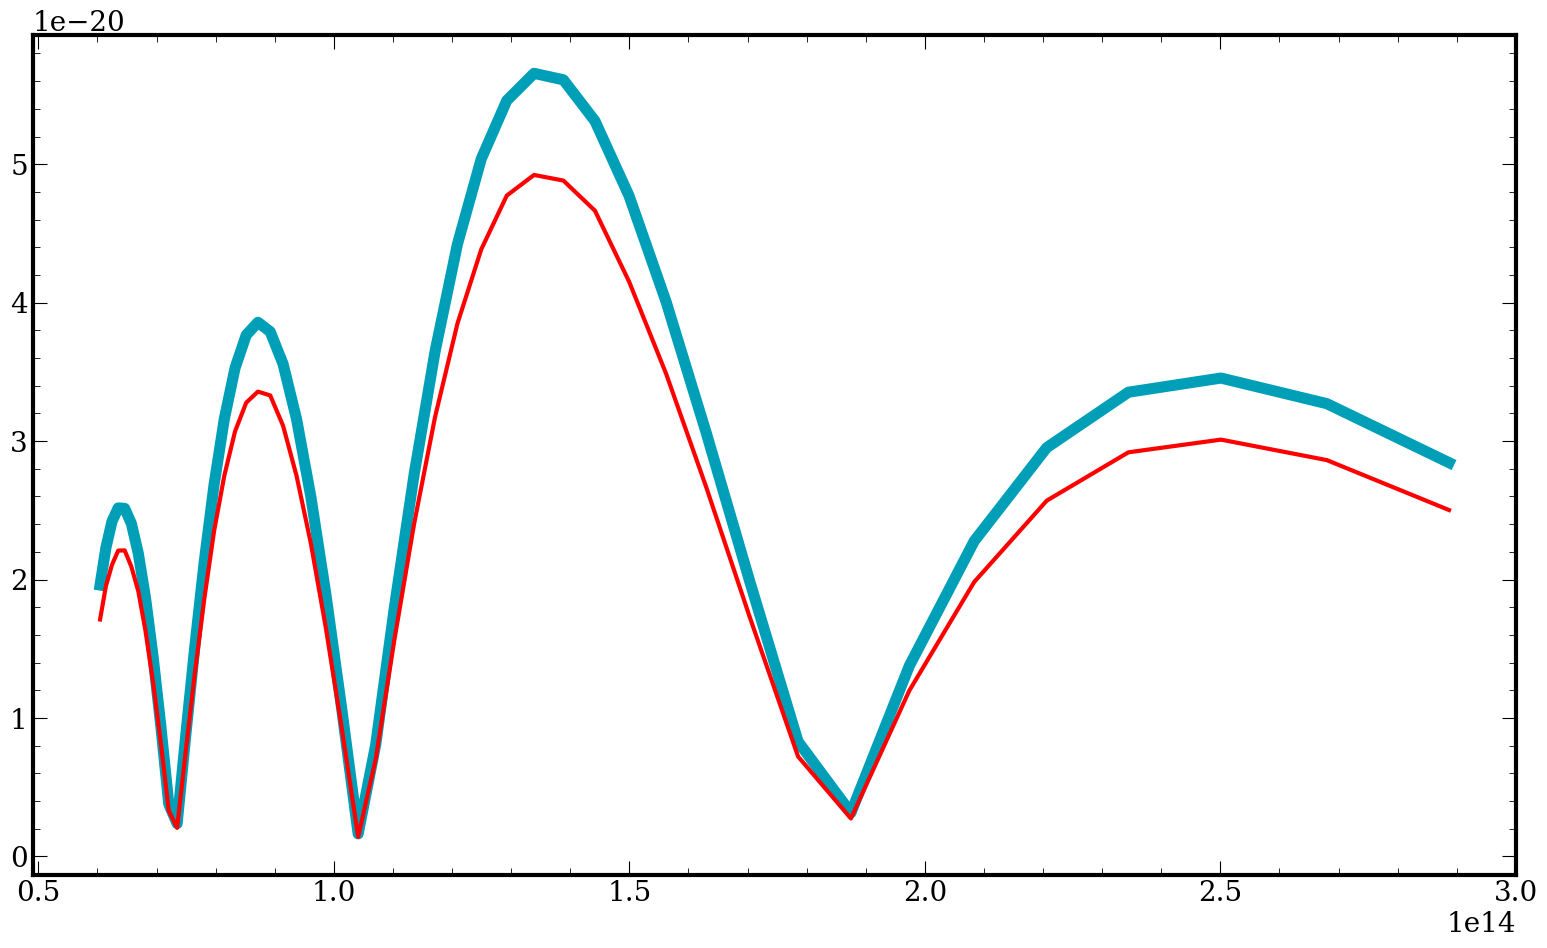

In [36]:
fig, ax = plt.subplots()
print(frequency_bin_centers.shape,fflux.shape)
ax.plot(frequency_bin_centers, fflux, linewidth=8)
ax.plot(frequency_bin_centers, jflux*200,color = 'red',linewidth = 3)

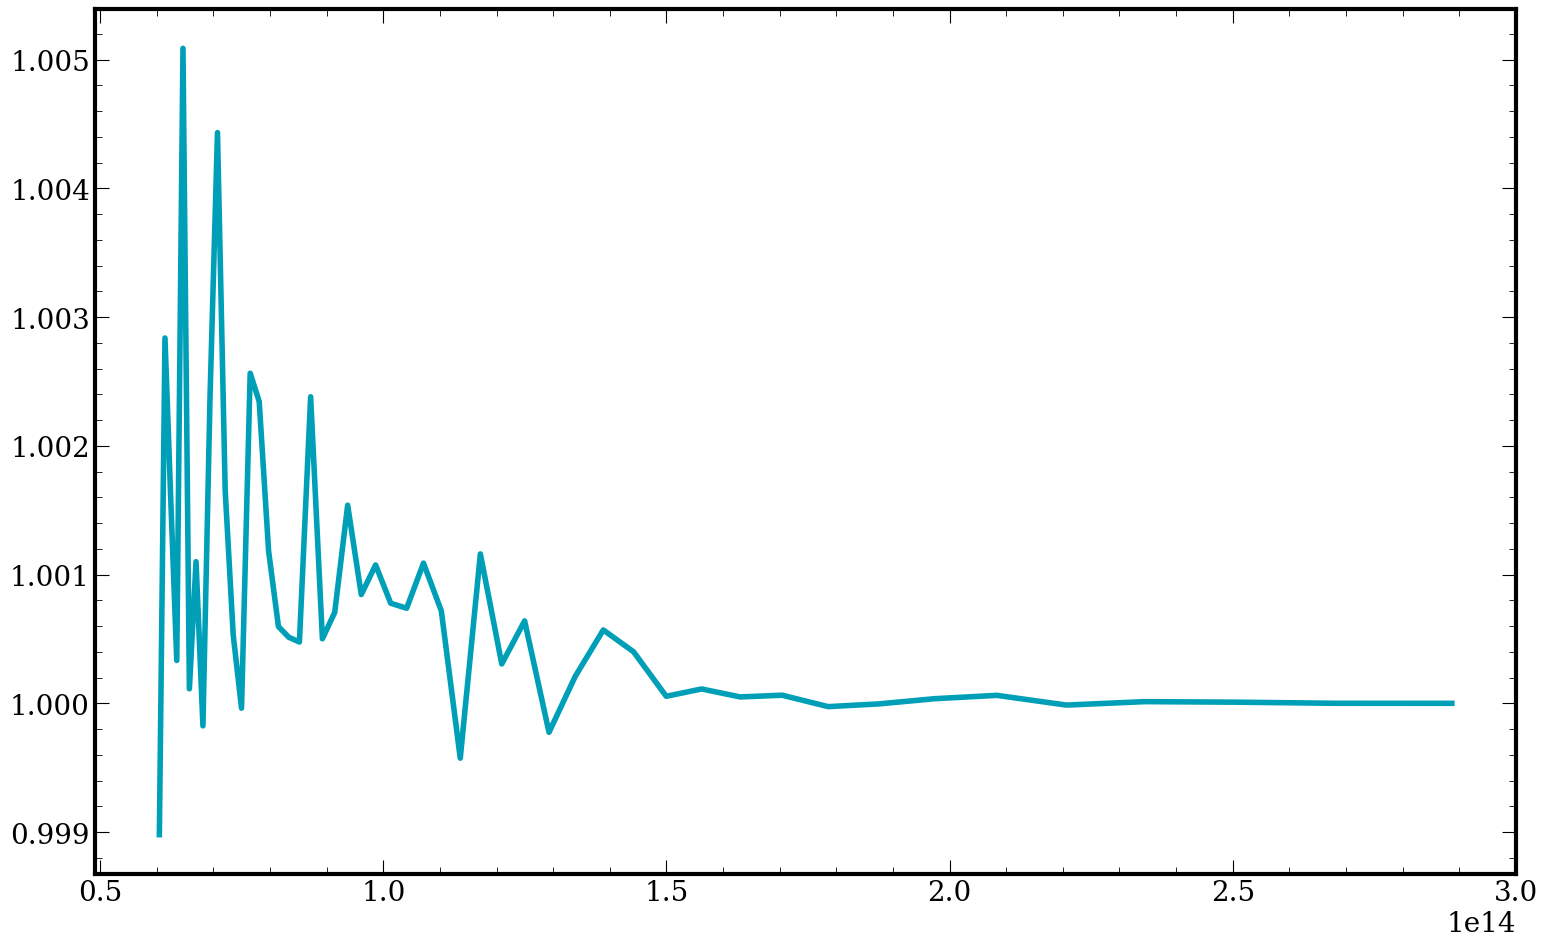

In [ ]:
fig, ax = plt.subplots()
ax.plot(frequency_bin_centers, fflux/jflux/1e-10, linewidth=4)
